# 06 - Decision Tree

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and test Decision Tree on the processed PhiUSIIL data (Experiment 1), compare different feature sets, and test the URL-only version on the external dataset (Experiment 2).

**About the model:** A Decision Tree asks a series of yes/no questions about the features, like "Is URLSimilarityIndex below 80?". Each answer leads to the next question until it reaches a final answer: phishing or legitimate. It is easy to understand and it does not need scaling.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

sys.path.append(str(Path("..").resolve()))
from src.data import get_feature_sets, load_train_test, load_url_experiment, sample_rows
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    make_cv,
    plot_confusion_matrix,
    save_results,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 188,296 rows | 69 features
Test set:     47,074 rows | 69 features


## Model Settings

We try different tree depths (how many questions the tree can ask) and the smallest number of URLs allowed in a leaf. A very deep tree can memorise the training data, so these settings help us control overfitting. That gives 12 combinations. A single tree is fast, so we tune on the full training set.

In [3]:
MODEL_NAME = "Decision Tree"
model = DecisionTreeClassifier(random_state=RANDOM_STATE)

param_grid = {
    "max_depth": [5, 10, 20, None],
    "min_samples_leaf": [1, 5, 10],
}

TUNING_SAMPLE_SIZE = None

## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'max_depth': 5, 'min_samples_leaf': 1}
Best cross-validation F1: 1.0000


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,1.0,0.0
Precision,1.0,0.0
Recall,1.0,0.0
F1,1.0,0.0
ROC-AUC,1.0,0.0


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.6 seconds


,Test Score
Accuracy,1.0
Precision,1.0
Recall,1.0
F1,1.0
ROC-AUC,1.0


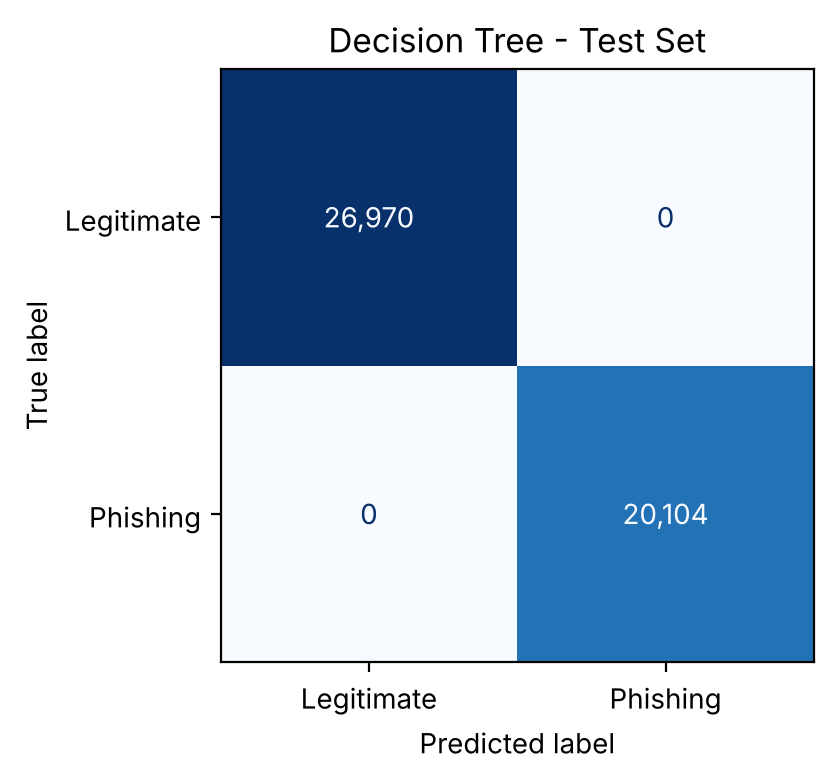

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

### Feature Importance

Tree models can tell us which features they used most to make decisions. We show the 15 most important features.

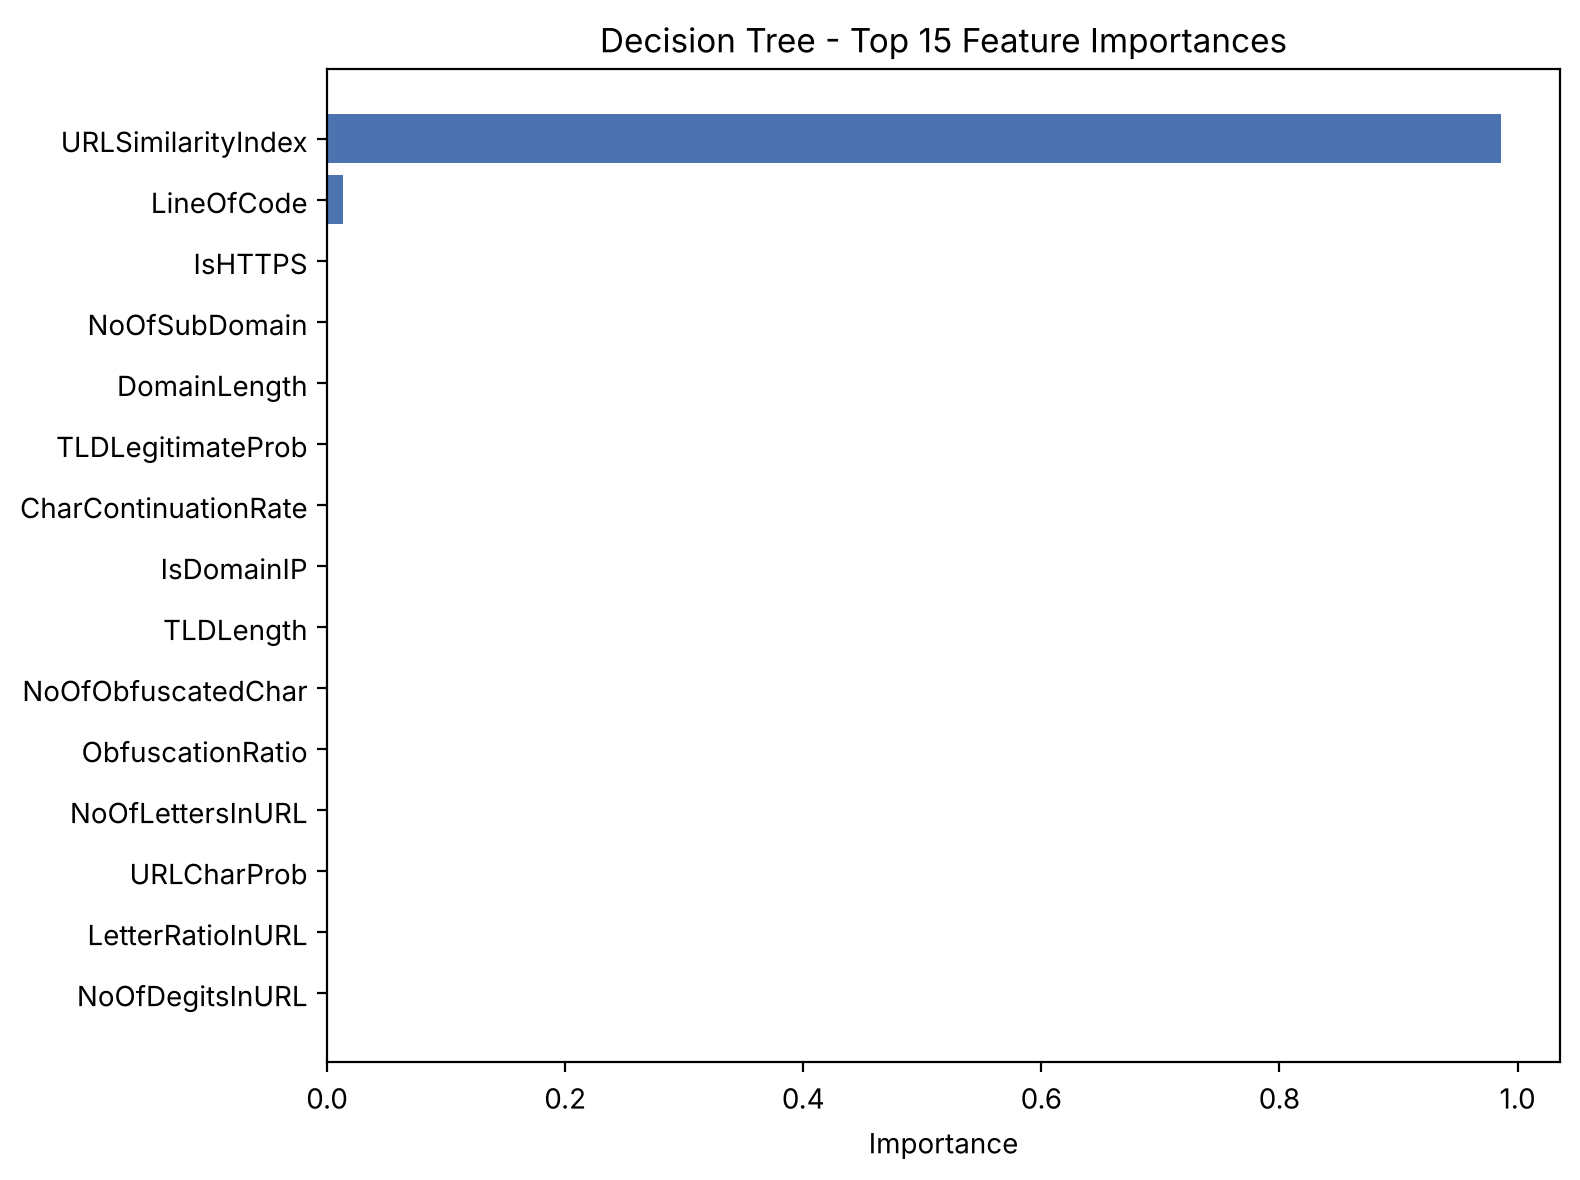

,Importance
URLSimilarityIndex,0.9863
LineOfCode,0.0132
IsHTTPS,0.0004
NoOfSubDomain,0.0000
DomainLength,0.0000
TLDLegitimateProb,0.0000
CharContinuationRate,0.0000
IsDomainIP,0.0000
TLDLength,0.0000
NoOfObfuscatedChar,0.0000


In [8]:
importance = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top_features = importance.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features.index[::-1], top_features.values[::-1], color="#4C72B0")
ax.set_title(f"{MODEL_NAME} - Top 15 Feature Importances")
ax.set_xlabel("Importance")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "decision_tree_feature_importance.png", dpi=300)
plt.show()

top_features.round(4).to_frame("Importance")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,1.0000,1.0000,1.0000,1.0000,1.0000
Original features only,1.0000,1.0000,1.0000,1.0000,1.0000
Without URLSimilarityIndex,0.9948,0.9882,0.9998,0.9939,0.9986


## 5. Experiment 2: URL Features Only

Here the model only uses the 18 URL features that we can create from any URL. We train it on PhiUSIIL and test it on both the PhiUSIIL test set and the external dataset. The difference between the two scores shows how well the model works on data from a different source.

In [10]:
X_url_train, X_url_test, X_external, y_url_train, y_url_test, y_external = load_url_experiment()

url_model = clone(best_model).fit(X_url_train, y_url_train)
url_results = {
    "PhiUSIIL test set": evaluate_model(url_model, X_url_test, y_url_test),
    "External dataset": evaluate_model(url_model, X_external, y_external),
}
pd.DataFrame(url_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
PhiUSIIL test set,0.9950,0.9996,0.9887,0.9941,0.9946
External dataset,0.5023,0.5028,0.9926,0.6675,0.4988


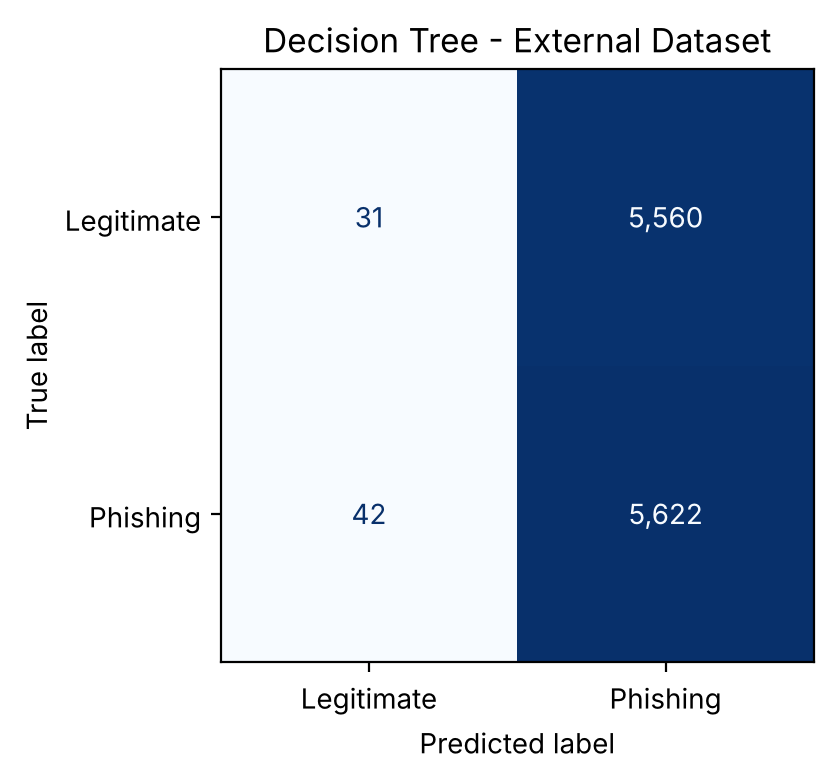

In [11]:
plot_confusion_matrix(y_external, url_model.predict(X_external), f"{MODEL_NAME} - External Dataset")

## 6. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [12]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - PhiUSIIL test set", **url_results["PhiUSIIL test set"]},
    {"Experiment": "URL features - External dataset", **url_results["External dataset"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,Decision Tree,Cross-validation,1.0000,1.0000,1.0000,1.0000,1.0000,NaN
1,Decision Tree,Test set - All features,1.0000,1.0000,1.0000,1.0000,1.0000,0.6433
2,Decision Tree,Test set - Original features only,1.0000,1.0000,1.0000,1.0000,1.0000,NaN
3,Decision Tree,Test set - Without URLSimilarityIndex,0.9948,0.9882,0.9998,0.9939,0.9986,NaN
4,Decision Tree,URL features - PhiUSIIL test set,0.9950,0.9996,0.9887,0.9941,0.9946,NaN
5,Decision Tree,URL features - External dataset,0.5023,0.5028,0.9926,0.6675,0.4988,NaN


## 7. Findings

- **Test score:** The Decision Tree made **no mistakes on the 47,074 test URLs** (accuracy 100%). Every phishing URL and every legitimate URL was classified correctly.
- **Stability:** The 5-fold cross-validation scores were the same in every fold (standard deviation 0), so the result is stable and not a lucky split.
- **Best settings:** `max_depth = 5` and `min_samples_leaf = 1`. A small tree with only 5 levels of questions was enough. A small tree is easier to understand and less likely to overfit.
- **Feature importance:** The tree depends almost completely on `URLSimilarityIndex` (about 99% of the importance). `LineOfCode` and `IsHTTPS` are used a little, and the other features are almost not used.
- **New features:** Using only the original features gave the same score, so our new features did not change the result for the Decision Tree.
- **Without `URLSimilarityIndex`:** Accuracy dropped to 99.48% (245 mistakes). The tree now called 240 legitimate URLs phishing. A single tree depends on its strongest feature much more than Random Forest does, which did not change at all without it.
- **Experiment 2 (URL features only):** The model scored 99.5% on the PhiUSIIL test set but only **50.2% on the external dataset**. It called 5,560 of the 5,591 legitimate external URLs phishing (recall 99.3%, precision 50.3%). This is the same distribution shift seen in all models: legitimate URLs in PhiUSIIL are mostly home pages, but in the external dataset they are often inner pages. We will fix this by training on both datasets together.